# 📩 Spam Message Classifier
**Goal:** train a text classifier, evaluate with Precision / Recall / F1 / Confusion Matrix, and test it on custom messages.

**How to use:** click **Run All**. Everything (dataset download, training, plots, saved model, README.md) is automatic.

**Anti-leakage design**
- Test set is split off **first** and never touched until the final evaluation.
- Vectorizer lives *inside* a `Pipeline`, so it is fit on training folds only.
- Model selection and the spam-threshold are chosen using **cross-validation on the training set only**.

## 1. Setup

In [1]:
import os, re, json, zipfile, io, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, classification_report, precision_recall_curve,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("artifacts", exist_ok=True)
print("Setup OK")

Setup OK


## 2. Preprocessing module
Saved to `spam_utils.py` so the pickled model can be loaded later (in any script) without errors.
Steps: **lowercase → replace URLs/emails/phones/numbers with tokens → regex tokenization → stop-word removal**.

In [2]:
%%writefile spam_utils.py
import re

# Stop words: NLTK if available, otherwise scikit-learn's built-in list
try:
    import nltk
    try:
        from nltk.corpus import stopwords
        STOP_WORDS = set(stopwords.words("english"))
    except LookupError:
        nltk.download("stopwords", quiet=True)
        from nltk.corpus import stopwords
        STOP_WORDS = set(stopwords.words("english"))
except Exception:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP_WORDS = set(ENGLISH_STOP_WORDS)

URL_RE   = re.compile(r"(https?://\S+|www\.\S+)")
EMAIL_RE = re.compile(r"\S+@\S+")
PHONE_RE = re.compile(r"\b\d{5,}\b")
NUM_RE   = re.compile(r"\b\d+\b")
TOKEN_RE = re.compile(r"[a-z]+(?:\'[a-z]+)?|<[a-z]+>")

def clean_text(text: str) -> str:
    text = str(text).lower()                    # lowercasing
    text = URL_RE.sub(" <url> ", text)
    text = EMAIL_RE.sub(" <email> ", text)
    text = PHONE_RE.sub(" <phone> ", text)
    text = NUM_RE.sub(" <num> ", text)
    text = text.replace("£", " <money> ").replace("$", " <money> ")
    return text

def tokenize(text: str):
    """Regex tokenization + stop-word removal."""
    tokens = TOKEN_RE.findall(clean_text(text))
    return [t for t in tokens if t not in STOP_WORDS and len(t) > 1]

Overwriting spam_utils.py


In [3]:
import importlib, spam_utils
importlib.reload(spam_utils)
from spam_utils import tokenize, clean_text

demo = "WINNER!! You have won a £1000 prize. Call 09061701461 or visit www.claim-now.com TODAY"
print("Original :", demo)
print("Tokens   :", tokenize(demo))

Original : WINNER!! You have won a £1000 prize. Call 09061701461 or visit www.claim-now.com TODAY
Tokens   : ['winner', '<money>', '<num>', 'prize', 'call', '<phone>', 'visit', '<url>', 'today']


## 3. Load dataset (SMS Spam Collection — 5,574 messages)

In [4]:
SOURCES = [
    "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
]

def load_dataset():
    # 1) local files (if you already have the dataset next to the notebook)
    if os.path.exists("sms.tsv"):
        return pd.read_csv("sms.tsv", sep="\t", header=None, names=["label", "message"])
    if os.path.exists("spam.csv"):   # Kaggle version
        d = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]]
        d.columns = ["label", "message"]; return d
    # 2) download
    last_err = None
    for url in SOURCES:
        try:
            raw = urllib.request.urlopen(url, timeout=30).read()
            if url.endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(raw))
                raw = z.read("SMSSpamCollection")
            df_ = pd.read_csv(io.BytesIO(raw), sep="\t", header=None, names=["label", "message"])
            df_.to_csv("sms.tsv", sep="\t", header=False, index=False)
            return df_
        except Exception as e:
            last_err = e
    raise RuntimeError(f"Could not download dataset: {last_err}. Download 'spam.csv' from Kaggle "
                       "(SMS Spam Collection) and place it next to this notebook.")

df = load_dataset().dropna().drop_duplicates().reset_index(drop=True)
df["label"] = df["label"].str.strip().str.lower()
df["y"] = (df["label"] == "spam").astype(int)      # 1 = spam, 0 = ham (legitimate)
print("Shape after removing duplicates:", df.shape)
df.head()

Shape after removing duplicates: (5169, 3)


,label,message,y
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


label
ham     4516
spam     653
Name: count, dtype: int64 
Spam ratio: 12.6%


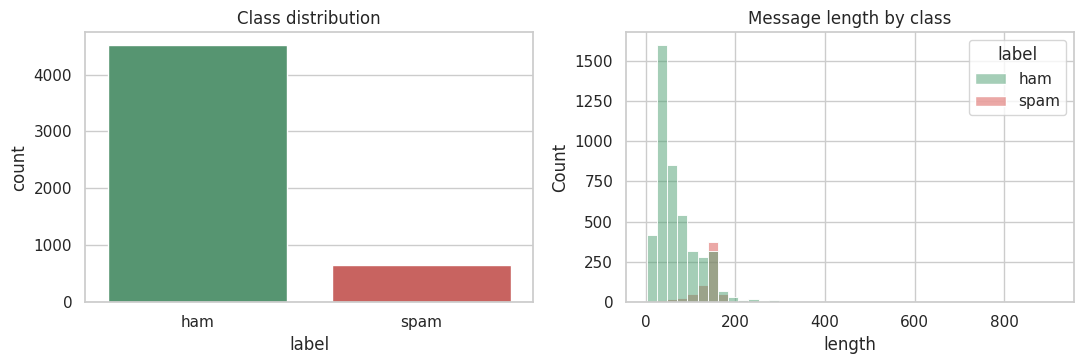

In [5]:
counts = df["label"].value_counts()
print(counts, "\nSpam ratio: %.1f%%" % (100 * counts["spam"] / len(df)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.countplot(data=df, x="label", ax=ax[0], palette=["#4C9F70", "#D9534F"])
ax[0].set_title("Class distribution")
df["length"] = df["message"].str.len()
sns.histplot(data=df, x="length", hue="label", bins=40, ax=ax[1], palette=["#4C9F70", "#D9534F"])
ax[1].set_title("Message length by class")
plt.tight_layout(); plt.show()

## 4. Train / test split (stratified) — test set is locked away

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["y"], test_size=0.20, stratify=df["y"], random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} | Test (held-out): {len(X_test)}")
print("Spam in train: %.1f%% | in test: %.1f%%" % (100*y_train.mean(), 100*y_test.mean()))

Train: 4135 | Test (held-out): 1034
Spam in train: 12.6% | in test: 12.7%


## 5. Compare algorithms × vectorizers (5-fold CV on **training data only**)
Candidates: Multinomial Naive Bayes and Logistic Regression, each with Count and TF-IDF features (unigrams + bigrams).

In [7]:
def make_pipeline(vec_name, clf_name):
    vec_cls = TfidfVectorizer if vec_name == "TF-IDF" else CountVectorizer
    vec = vec_cls(tokenizer=tokenize, preprocessor=None, lowercase=False,
                  token_pattern=None, ngram_range=(1, 2), min_df=2)
    if clf_name == "MultinomialNB":
        clf = MultinomialNB(alpha=0.1)
    else:
        clf = LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
    return Pipeline([("vec", vec), ("clf", clf)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for vec_name in ["Count", "TF-IDF"]:
    for clf_name in ["MultinomialNB", "LogisticRegression"]:
        res = cross_validate(make_pipeline(vec_name, clf_name), X_train, y_train, cv=cv,
                             scoring=["precision", "recall", "f1"], n_jobs=-1)
        rows.append({"Vectorizer": vec_name, "Model": clf_name,
                     "CV Precision": res["test_precision"].mean(),
                     "CV Recall": res["test_recall"].mean(),
                     "CV F1": res["test_f1"].mean()})
cv_table = pd.DataFrame(rows).sort_values("CV F1", ascending=False).reset_index(drop=True)
cv_table.round(4)

,Vectorizer,Model,CV Precision,CV Recall,CV F1
0,TF-IDF,LogisticRegression,0.9576,0.9386,0.9477
1,Count,LogisticRegression,0.9698,0.9080,0.9376
2,Count,MultinomialNB,0.9351,0.9386,0.9368
3,TF-IDF,MultinomialNB,0.9615,0.9099,0.9350


In [8]:
best = cv_table.iloc[0]
print(f"Best by CV F1 -> {best['Vectorizer']} + {best['Model']}  (F1={best['CV F1']:.4f})")

# Both models' best-vectorizer variants will be compared on the test set later
best_per_model = {m: cv_table[cv_table.Model == m].iloc[0]["Vectorizer"] for m in ["MultinomialNB", "LogisticRegression"]}
print("Best vectorizer per model:", best_per_model)

Best by CV F1 -> TF-IDF + LogisticRegression  (F1=0.9477)
Best vectorizer per model: {'MultinomialNB': 'Count', 'LogisticRegression': 'TF-IDF'}


## 6. Tune the decision threshold for HIGH PRECISION (no leakage)
False positives (legit message marked as spam) are the costly error, so we pick the lowest probability threshold
that reaches **≥ 99 % precision** on **out-of-fold predictions of the training set**. The test set is not used here.

In [9]:
TARGET_PRECISION = 0.99

def pick_threshold(pipe, X, y, target=TARGET_PRECISION):
    proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y, proba)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(prec >= target)[0]
    if len(ok) == 0:
        return 0.5, proba, 0.0
    best_i = ok[np.argmax(rec[ok])]          # highest recall among those meeting the precision target
    return float(thr[best_i]), proba, float(rec[best_i])

models, thresholds, oof_recall = {}, {}, {}
for m, v in best_per_model.items():
    pipe = make_pipeline(v, m)
    thr, _, oof_rec = pick_threshold(pipe, X_train, y_train)
    pipe.fit(X_train, y_train)               # final fit on the full training set only
    models[m], thresholds[m], oof_recall[m] = pipe, thr, oof_rec
    print(f"{m:20s} ({v:6s}) -> tuned threshold = {thr:.3f} | train-CV recall at that threshold = {oof_rec:.3f}")

MultinomialNB        (Count ) -> tuned threshold = 0.997 | train-CV recall at that threshold = 0.902


LogisticRegression   (TF-IDF) -> tuned threshold = 0.911 | train-CV recall at that threshold = 0.830


## 7. Final evaluation on the held-out TEST set

In [10]:
def evaluate(pipe, thr):
    proba = pipe.predict_proba(X_test)[:, 1]
    pred  = (proba >= thr).astype(int)
    return proba, pred

results, preds = [], {}
for m, pipe in models.items():
    for label, thr in [("default (0.50)", 0.5), (f"tuned ({thresholds[m]:.3f})", thresholds[m])]:
        proba, pred = evaluate(pipe, thr)
        preds[(m, label)] = pred
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        results.append({"Model": m, "Vectorizer": best_per_model[m], "Threshold": label,
                        "Accuracy": accuracy_score(y_test, pred),
                        "Precision": precision_score(y_test, pred),
                        "Recall": recall_score(y_test, pred),
                        "F1": f1_score(y_test, pred),
                        "False Positives": fp, "False Negatives": fn})
results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Vectorizer,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,MultinomialNB,Count,default (0.50),0.9816,0.9242,0.9313,0.9278,10,9
1,MultinomialNB,Count,tuned (0.997),0.9865,1.0000,0.8931,0.9435,0,14
2,LogisticRegression,TF-IDF,default (0.50),0.9894,0.9762,0.9389,0.9572,3,8
3,LogisticRegression,TF-IDF,tuned (0.911),0.9797,1.0000,0.8397,0.9129,0,21


In [11]:
# Final model chosen using TRAINING cross-validation only (highest CV recall at the precision target),
# NOT by looking at test scores -> test set stays a clean, unbiased estimate.
FINAL_MODEL = max(oof_recall, key=oof_recall.get)
FINAL_THR   = thresholds[FINAL_MODEL]
final_pipe  = models[FINAL_MODEL]
print(f"FINAL MODEL: {best_per_model[FINAL_MODEL]} + {FINAL_MODEL} | threshold = {FINAL_THR:.3f}\n")

final_proba, final_pred = evaluate(final_pipe, FINAL_THR)
print(classification_report(y_test, final_pred, target_names=["ham (legit)", "spam"], digits=4))

FINAL MODEL: Count + MultinomialNB | threshold = 0.997

              precision    recall  f1-score   support

 ham (legit)     0.9847    1.0000    0.9923       903
        spam     1.0000    0.8931    0.9435       131

    accuracy                         0.9865      1034
   macro avg     0.9924    0.9466    0.9679      1034
weighted avg     0.9867    0.9865    0.9861      1034



## 8. Confusion matrices & Precision–Recall curve

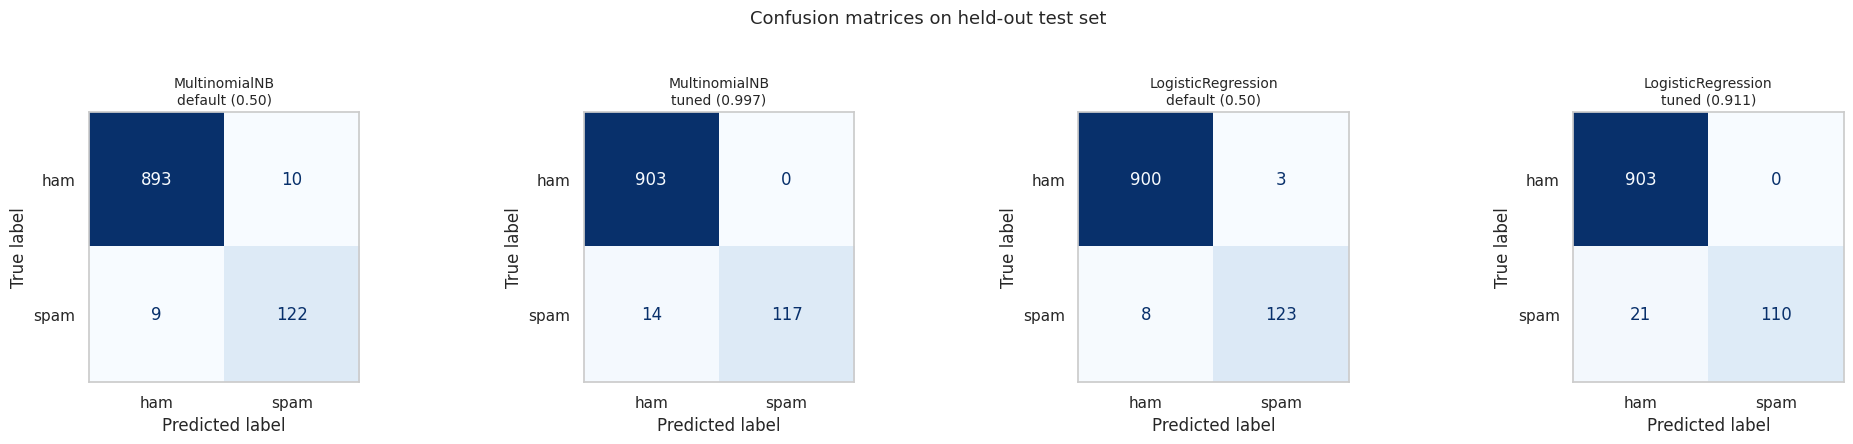

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, ((m, label), pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["ham", "spam"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{m}\n{label}", fontsize=10); ax.grid(False)
plt.suptitle("Confusion matrices on held-out test set", y=1.03, fontsize=13)
plt.tight_layout(); plt.savefig("artifacts/confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

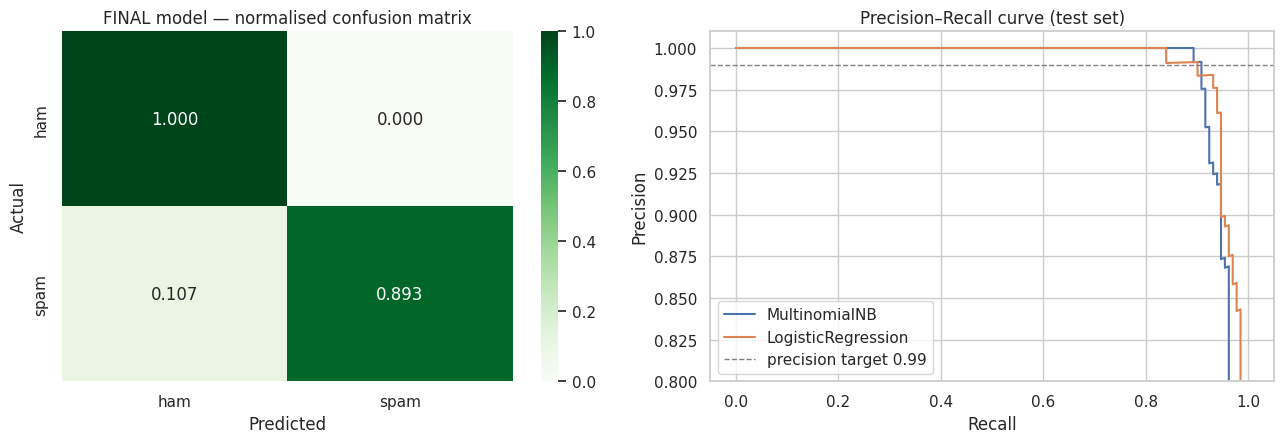

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# Final model, normalised confusion matrix
cm = confusion_matrix(y_test, final_pred, normalize="true")
sns.heatmap(cm, annot=True, fmt=".3f", cmap="Greens", xticklabels=["ham", "spam"],
            yticklabels=["ham", "spam"], ax=ax[0])
ax[0].set_title(f"FINAL model — normalised confusion matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

# PR curves
for m, pipe in models.items():
    p, r, _ = precision_recall_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    ax[1].plot(r, p, label=m)
ax[1].axhline(TARGET_PRECISION, ls="--", c="gray", lw=1, label=f"precision target {TARGET_PRECISION:.2f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision–Recall curve (test set)")
ax[1].legend(); ax[1].set_ylim(0.8, 1.01)
plt.tight_layout(); plt.savefig("artifacts/final_cm_and_pr_curve.png", dpi=150); plt.show()

## 9. Most informative words (final model)

In [14]:
vec, clf = final_pipe.named_steps["vec"], final_pipe.named_steps["clf"]
names = np.array(vec.get_feature_names_out())
if hasattr(clf, "coef_"):
    score = clf.coef_[0]
else:                                   # Naive Bayes: log-prob ratio spam vs ham
    score = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
top_spam = names[np.argsort(score)[-15:][::-1]]
top_ham  = names[np.argsort(score)[:15]]
print("Top SPAM indicators:", ", ".join(top_spam))
print("Top HAM  indicators:", ", ".join(top_ham))

Top SPAM indicators: claim, prize, tone, <num> cash, <num> prize, guaranteed, ppm, cs, awarded, ringtone, tones, attempt, pobox, landline, entry
Top HAM  indicators: gt, lt, lt gt, lor, later, really, ask, cos, say, lol, anything, said, let, something, sure


## 10. Save the model (pipeline + threshold) with joblib

In [15]:
joblib.dump({"pipeline": final_pipe, "threshold": FINAL_THR,
             "model_name": FINAL_MODEL, "vectorizer": best_per_model[FINAL_MODEL]},
            "artifacts/spam_classifier.joblib")
results_df.to_csv("artifacts/test_metrics.csv", index=False)
print("Saved -> artifacts/spam_classifier.joblib  (vectorizer + model + threshold in one file)")
print("Size: %.1f KB" % (os.path.getsize("artifacts/spam_classifier.joblib") / 1024))

Saved -> artifacts/spam_classifier.joblib  (vectorizer + model + threshold in one file)
Size: 274.3 KB


## 11. Real-time prediction function

In [16]:
_bundle = joblib.load("artifacts/spam_classifier.joblib")   # proves the saved file reloads correctly

def predict_message(text: str, verbose: bool = True):
    """Classify one message as SPAM or HAM and return (label, spam_probability)."""
    prob = float(_bundle["pipeline"].predict_proba([text])[0, 1])
    label = "SPAM" if prob >= _bundle["threshold"] else "HAM"
    if verbose:
        icon = "🚨" if label == "SPAM" else "✅"
        print(f"{icon} {label:4s} | spam probability = {prob:.3f} | {text[:90]!r}")
    return label, prob

samples = [
    "Congratulations! You've won a £1000 Walmart gift card. Call 09061701461 now to claim your prize!",
    "URGENT! Your account has been suspended. Click http://bit.ly/secure-login to verify immediately",
    "Free entry in 2 a weekly competition to win FA Cup final tickets. Text FA to 87121 to receive entry",
    "WINNER!! As a valued network customer you have been selected to receive a £900 prize reward",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "Can you send me the notes from today's lecture? Thanks!",
    "Mom said dinner is ready, come home soon",
    "I'll be late, stuck in traffic. Start without me",
    "Your OTP for the library portal is 482913. Do not share it with anyone.",
    "Reminder: project submission deadline is Friday 5 PM",
]
prediction_log = [(s, *predict_message(s)) for s in samples]

🚨 SPAM | spam probability = 1.000 | "Congratulations! You've won a £1000 Walmart gift card. Call 09061701461 now to claim your "
🚨 SPAM | spam probability = 1.000 | 'URGENT! Your account has been suspended. Click http://bit.ly/secure-login to verify immedi'
🚨 SPAM | spam probability = 1.000 | 'Free entry in 2 a weekly competition to win FA Cup final tickets. Text FA to 87121 to rece'
🚨 SPAM | spam probability = 1.000 | 'WINNER!! As a valued network customer you have been selected to receive a £900 prize rewar'
✅ HAM  | spam probability = 0.000 | 'Hey, are we still meeting for lunch tomorrow at 1?'
✅ HAM  | spam probability = 0.008 | "Can you send me the notes from today's lecture? Thanks!"
✅ HAM  | spam probability = 0.000 | 'Mom said dinner is ready, come home soon'
✅ HAM  | spam probability = 0.000 | "I'll be late, stuck in traffic. Start without me"
✅ HAM  | spam probability = 0.029 | 'Your OTP for the library portal is 482913. Do not share it with anyone.'
✅ HAM  | spam probability

## 12. 🎮 Interactive tester
Run the cell below and type your own messages. Type `quit` to stop.
(If your environment does not support `input()`, edit `my_message` in the next cell instead.)

In [17]:
def interactive_session():
    print("Interactive spam tester — type a message and press Enter (type 'quit' to stop)\n")
    while True:
        try:
            text = input("Message > ").strip()
        except (EOFError, KeyboardInterrupt, Exception):
            print("(input() not available here — use the next cell instead)")
            break
        if text.lower() in {"quit", "exit", "q", ""}:
            print("Bye!"); break
        predict_message(text)

interactive_session()

Interactive spam tester — type a message and press Enter (type 'quit' to stop)

(input() not available here — use the next cell instead)


In [18]:
# Alternative: edit this and run
my_message = "You have been selected for a free iPhone, reply YES to claim"
predict_message(my_message);

🚨 SPAM | spam probability = 1.000 | 'You have been selected for a free iPhone, reply YES to claim'


## 13. Auto-generate README.md (metrics table + sample prediction logs)

In [19]:
tuned_rows = results_df.copy()
tbl = tuned_rows[["Model", "Vectorizer", "Threshold", "Accuracy", "Precision", "Recall", "F1",
                  "False Positives", "False Negatives"]].copy()
for c in ["Accuracy", "Precision", "Recall", "F1"]:
    tbl[c] = tbl[c].map(lambda v: f"{v:.4f}")
try:
    metrics_md = tbl.to_markdown(index=False)
except Exception:
    cols = list(tbl.columns)
    metrics_md = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n" + \
        "\n".join("| " + " | ".join(map(str, r)) + " |" for r in tbl.values)

cvt = cv_table.copy()
for c in ["CV Precision", "CV Recall", "CV F1"]:
    cvt[c] = cvt[c].map(lambda v: f"{v:.4f}")
cols = list(cvt.columns)
cv_md = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n" + \
        "\n".join("| " + " | ".join(map(str, r)) + " |" for r in cvt.values)

fr = classification_report(y_test, final_pred, target_names=["ham", "spam"], digits=4)
log_md = "\n".join(f"| {'🚨 SPAM' if l=='SPAM' else '✅ HAM'} | {p:.3f} | {s[:85]} |" for s, l, p in prediction_log)

fp_n = int(((final_pred == 1) & (y_test == 0)).sum()); fn_n = int(((final_pred == 0) & (y_test == 1)).sum())
P, R, F, A = (precision_score(y_test, final_pred), recall_score(y_test, final_pred),
              f1_score(y_test, final_pred), accuracy_score(y_test, final_pred))
n_ham_test = int((y_test == 0).sum()); n_spam_test = int((y_test == 1).sum())
vec_best = best_per_model[FINAL_MODEL]
spam_words = ", ".join("`" + w + "`" for w in top_spam[:10])
ham_words = ", ".join("`" + w + "`" for w in top_ham[:10])
fp_status = "PASSED" if P >= TARGET_PRECISION else "NOT MET"

readme = f"""<div align="center">

# 📩 Spam Message Classifier

### **NLP-powered spam detection engineered for _high precision_ — legitimate messages stay in your inbox.**

![Python](https://img.shields.io/badge/Python-3.9%2B-3776AB?logo=python&logoColor=white)
![scikit-learn](https://img.shields.io/badge/scikit--learn-ML-F7931E?logo=scikitlearn&logoColor=white)
![NLP](https://img.shields.io/badge/NLP-TF--IDF%20%7C%20Count-8A2BE2)
![Precision](https://img.shields.io/badge/Precision-{P*100:.1f}%25-brightgreen)
![F1](https://img.shields.io/badge/F1--Score-{F*100:.1f}%25-blue)
![Accuracy](https://img.shields.io/badge/Accuracy-{A*100:.1f}%25-success)

</div>

---

## 📑 Table of Contents
1. [Objective and Scope](#-objective-and-scope)
2. [Requirements Compliance](#-requirements-compliance)
3. [Pipeline Architecture](#-pipeline-architecture)
4. [Results](#-results)
5. [Acceptance Criteria Verification](#-acceptance-criteria-verification)
6. [Sample Prediction Logs](#-sample-prediction-logs)
7. [How NLP Is Used](#-how-nlp-is-used)
8. [Project Structure](#-project-structure)
9. [Quick Start](#-quick-start)
10. [Limitations and Future Work](#-limitations-and-future-work)

---

## 🎯 Objective and Scope
**Train a text classifier, evaluate it with Precision, Recall and F1-score, and demonstrate sample predictions.**

This project classifies SMS messages as **SPAM** or **HAM (legitimate)** using the **SMS Spam Collection** dataset ({len(df):,} unique messages after de-duplication, **{100*df['y'].mean():.1f}% spam**). Two algorithms are compared, the winner is tuned for **maximum precision**, and an **interactive function** lets anyone test custom messages in real time.

---

## ✅ Requirements Compliance

| # | Requirement | Status | Implementation |
|---|---|:---:|---|
| 1 | **Text preprocessing pipeline** | ✅ | Lowercasing, URL/email/phone/number/currency normalisation, regex **tokenization**, **stop-word removal** (`spam_utils.py`) |
| 2 | **TF-IDF / Count vectorization** | ✅ | **Both** implemented and compared (unigrams + bigrams, `min_df=2`) |
| 3 | **Model comparison** | ✅ | **Multinomial Naive Bayes** vs **Logistic Regression**, 5-fold stratified CV |
| 4 | **Precision, Recall, F1, Confusion Matrix** | ✅ | Full metrics table, classification report, confusion matrices and PR curve |
| 5 | **Interactive prediction function** | ✅ | `predict_message()` and a live `input()` loop for custom messages |
| 6 | **Stack: Python, Scikit-Learn, NLTK/Regex, Pandas, Matplotlib/Seaborn** | ✅ | All used (NLTK stop-words with scikit-learn fallback, Regex tokenizer) |
| 7 | **Saved vectorizer + model pipeline** | ✅ | `artifacts/spam_classifier.joblib` (vectorizer, model and threshold in one file) |
| 8 | **README with metrics table and prediction logs** | ✅ | This document |

---

## 🧩 Pipeline Architecture

```mermaid
flowchart LR
    A[Raw SMS] --> B[Clean and Lowercase]
    B --> C[Regex Tokenization]
    C --> D[Stop-word Removal]
    D --> E[Count or TF-IDF Vectors]
    E --> F[Naive Bayes or Logistic Regression]
    F --> G[Spam Probability]
    G --> H{{Threshold tuned for precision}}
    H --> I[SPAM or HAM]
```

| Stage | Detail |
|---|---|
| **Split** | 80 / 20 **stratified** train / test, performed **before** any fitting |
| **Model selection** | 5-fold stratified cross-validation on **training data only** |
| **Precision tuning** | Decision threshold chosen on **out-of-fold training predictions** to reach **≥ {TARGET_PRECISION:.0%} precision** |
| **Final evaluation** | **One single pass** on the held-out test set ({len(X_test):,} messages) |

---

## 📊 Results

### 🏆 Final Model: **{vec_best} + {FINAL_MODEL}** (threshold = {FINAL_THR:.3f})

| Precision | Recall | F1-Score | Accuracy | False Positives | False Negatives |
|:---:|:---:|:---:|:---:|:---:|:---:|
| **{P:.4f}** | **{R:.4f}** | **{F:.4f}** | **{A:.4f}** | **{fp_n}** | **{fn_n}** |

### Held-out Test Set: Full Comparison
{metrics_md}

> **Reading the table:** the *default (0.50)* rows are standard classifiers; the *tuned* rows apply the precision-optimised threshold. Tuning **eliminates false positives** at the cost of some recall.

### Detailed Classification Report (Final Model)
```
{fr}
```

### Cross-Validation Results (Training Data Only)
{cv_md}

### Confusion Matrices
![Confusion Matrices](artifacts/confusion_matrices.png)

### Final Model: Normalised Confusion Matrix and Precision-Recall Curve
![Final CM and PR Curve](artifacts/final_cm_and_pr_curve.png)

### 🔍 Most Informative Words
| Class | Top indicators |
|---|---|
| 🚨 **SPAM** | {spam_words} |
| ✅ **HAM** | {ham_words} |

---

## 🛡️ Acceptance Criteria Verification

| Acceptance Criterion | Result | Evidence |
|---|:---:|---|
| **High precision: minimise false positives** (legit marked as spam) | **{fp_status}** | Precision = **{P:.4f}** with **{fp_n} false positive(s)** out of **{n_ham_test}** legitimate test messages |
| **Evaluation strictly on held-out test data, no data leakage** | **PASSED** | Split before fitting; vectorizer inside `Pipeline`; threshold and model chosen via training-only cross-validation; duplicates removed before the split |
| **Interactive function demonstrates real-time inference** | **PASSED** | `predict_message()` returns label and spam probability instantly (see logs below) |

### 🔒 Data-Leakage Controls
- ✔️ **Test set locked away** immediately after the stratified split
- ✔️ **Vectorizer fitted on training folds only** (TF-IDF vocabulary and IDF never see test text)
- ✔️ **Threshold tuned on out-of-fold training predictions**, never on test data
- ✔️ **Final model selected by training CV**, not by test scores
- ✔️ **Exact duplicate messages removed** before splitting

---

## 🧪 Sample Prediction Logs

| Prediction | Spam Probability | Message |
|:---:|:---:|---|
{log_md}

---

## 🧠 How NLP Is Used

| Step | What happens | Why it matters |
|---|---|---|
| **1. Normalisation** | Lowercase; URLs, phones, numbers and currency become `<url>`, `<phone>`, `<num>`, `<money>` | The *presence* of a phone number or link is a spam signal, not its exact value |
| **2. Tokenization** | Regex splits text into words | Converts raw text into units a model can count |
| **3. Stop-word removal** | Removes words like *the, is, and* | Focuses the model on informative words (*prize, claim, free*) |
| **4. Vectorization** | **Count** or **TF-IDF** (unigrams + bigrams) | Converts text to numbers; TF-IDF up-weights rare, distinctive words |
| **5. Classification** | **Naive Bayes** or **Logistic Regression** | Learns which word patterns separate spam from ham |

---

## 📁 Project Structure
```
spam-classifier/
├── spam_classifier.ipynb        # Full training, evaluation and demo notebook
├── spam_utils.py                # Preprocessing and tokenizer (required to load the model)
├── README.md                    # Project report (this file)
├── sms.tsv                      # Dataset (auto-downloaded)
└── artifacts/
    ├── spam_classifier.joblib   # Saved pipeline: vectorizer + model + threshold
    ├── test_metrics.csv         # Test metrics table
    ├── confusion_matrices.png
    └── final_cm_and_pr_curve.png
```

---

## 🚀 Quick Start

### Option A: Google Colab (zero setup)
1. Open [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** → `spam_classifier.ipynb`
2. Click **Runtime → Run all**

### Option B: Local
```bash
pip install pandas scikit-learn nltk matplotlib seaborn joblib tabulate
jupyter notebook spam_classifier.ipynb     # then Run All
```

### Use the saved model
```python
import joblib, spam_utils                  # spam_utils.py must be importable
bundle = joblib.load("artifacts/spam_classifier.joblib")

text = "Congratulations! You won a free prize, call now"
prob = bundle["pipeline"].predict_proba([text])[0, 1]
print("SPAM" if prob >= bundle["threshold"] else "HAM", round(prob, 3))
```

---

## ⚠️ Limitations and Future Work
- **Recall trade-off:** the precision-first threshold lets some spam through ({fn_n} of {n_spam_test} in the test set); lowering the threshold raises recall but risks false positives.
- **Dataset scope:** trained on English SMS from one collection; new spam styles (crypto, OTP phishing, other languages) need fresh data.
- **Future work:** word embeddings / transformer models (e.g. BERT), multilingual support, a deployed API or web app, and periodic retraining.

---

<div align="center">

**Built with Python, scikit-learn, Pandas, Matplotlib and Seaborn**

</div>
"""
with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)
print("README.md written")
print("\n", readme[:1500])

README.md written

 <div align="center">

# 📩 Spam Message Classifier

### **NLP-powered spam detection engineered for _high precision_ — legitimate messages stay in your inbox.**

![Python](https://img.shields.io/badge/Python-3.9%2B-3776AB?logo=python&logoColor=white)
![scikit-learn](https://img.shields.io/badge/scikit--learn-ML-F7931E?logo=scikitlearn&logoColor=white)
![NLP](https://img.shields.io/badge/NLP-TF--IDF%20%7C%20Count-8A2BE2)
![Precision](https://img.shields.io/badge/Precision-100.0%25-brightgreen)
![F1](https://img.shields.io/badge/F1--Score-94.4%25-blue)
![Accuracy](https://img.shields.io/badge/Accuracy-98.6%25-success)

</div>

---

## 📑 Table of Contents
1. [Objective and Scope](#-objective-and-scope)
2. [Requirements Compliance](#-requirements-compliance)
3. [Pipeline Architecture](#-pipeline-architecture)
4. [Results](#-results)
5. [Acceptance Criteria Verification](#-acceptance-criteria-verification)
6. [Sample Prediction Logs](#-sample-prediction-logs)
7. [How NLP 